# Reading vs shadow-typing: pre/post test analysis (minimal)

In [1]:
import re, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(".")          # folder that holds the six exports
FIG_DIR = Path(".")           # folder the last cell exports the graphs to (PNG and PDF)
PRE_FILES = {"Random Question CP.csv": ["Computer Science", "Psychology"],     # questions 1-16, then 17-32
             "Random Question CE.csv": ["Computer Science", "Education"],
             "Random Question EP.csv": ["Education", "Psychology"]}
POST_FILES = {"Post-Questions 1.csv": "Computer Science", "Post-Question 2.csv": "Education",
              "Post-Question 3.csv": "Psychology"}
CODE_COL = "What is your participation code?"
ALIASES = {"RvT_P02": "RvsT_P02"}     # one participant typed a slightly different code in some forms
pd.set_option("display.width", 200)

KEY = {
"Computer Science": [
 "By sending messages to one another over the network",
 "getting every computer to agree on the same value or state",
 "every computer that has not failed must eventually choose the same value",
 "the chosen value was actually proposed by one of the computers",
 "may behave in arbitrary ways, even sending conflicting information to different machines",
 "No such procedure can guarantee that, in every possible run, the working computers eventually reach a decision, if even one computer might fail",
 "Any two majorities share at least one computer, so if the computers follow the rules, two conflicting values cannot both be finalised",
 "Start from the same state and run the same deterministic program, applying the same operations in the same order",
 "alternate between spells of unlimited delay and spells when messages arrive within some limited time",
 "proposers, acceptors, and learners",
 "twice that number of computers, plus one",
 "stored on a majority of the computers",
 "make it unlikely that several computers try to lead at once, avoiding repeated tied votes",
 "more than three times that number of computers",
 "pre-prepare, prepare, and commit",
 "the other computers switch to a new leader through a 'view-change"],
"Education": [
 "very limited",
 "about seven items",
 "almost unlimited and long-lasting",
 "an organised mental structure that combines many separate pieces into one meaningful unit",
 "A familiar unit is handled as a single item, so an expert deals with as one chunk what a beginner sees as many separate pieces",
 "Understanding breaks down and little lasting learning happens",
 "Studying fully worked-out examples rather than solving many problems unaided",
 "wastes limited mental effort and slows learning down",
 "the difficulty that is inherent in the material itself",
 "how many separate pieces of information must be held and connected in mind at the same time",
 "An expert groups several pieces into one familiar unit, which lowers the load they actually feel",
 "the way the material is presented, rather than the difficulty of the topic itself",
 "having to hold the starting point, the goal, and the gap between them in mind all at once",
 "The mental effort deliberately spent on building and automating understanding",
 "the 'useful' effort had no separate source of its own, unlike the other two kinds",
 "become useless or even unhelpful, because it repeats what they already know"],
"Psychology": [
 "deciding whether a faint signal is really there when it can be confused with background noise",
 "practical work on radar and electronic signals",
 "says a signal is there when in fact nothing is there",
 "fails to notice a signal that is really there",
 "one is simply more willing to say 'yes' than the other",
 "they catch more real signals but also raise their false alarms",
 "missing a real tumour is so serious that more false alarms are an acceptable price",
 "is simply more cautious about saying 'yes'",
 "two overlapping bell-shaped curves, with the 'signal' one shifted toward higher values",
 "the distance between the centres of the two curves, measured in standard-deviation units",
 "It measures how far apart the two curves sit, separately from how willing the person is to say 'yes'",
 "a cutoff point above which the person answers 'yes' and below which 'no'",
 "few false alarms but many misses",
 "measures usually written as 'beta' or 'c'",
 "the rate of correct 'yes' answers against the rate of false alarms, as the cutoff is varied",
 "wherever it gives the best expected payoff, weighing how likely the signal is against the costs and rewards"],
}
GUARD = {"Computer Science": (("distributed system",), ("primary",)),
         "Education":        (("hold in mind at once", "working memory"), ("expert",)),
         "Psychology":       (("signal detection",), ("ideal observer",))}

In [2]:
def norm(s):
    s = unicodedata.normalize("NFKC", str(s)).replace("’", "'").replace("‘", "'").lower()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]+", " ", s)).strip()

def classify(answer, correct):
    a = norm(answer)
    if not a or a in ("nan", "none"):
        return "blank"
    if a.startswith(("i m not sure", "im not sure")):
        return "not sure"
    return "correct" if a == norm(correct) else "wrong"

rows = []
def add(d, cols, topic, phase, f):
    first, last = GUARD[topic]                      # questions must be in the expected order
    assert any(k in cols[0].lower() for k in first) and any(k in cols[15].lower() for k in last), f"{f}: {topic} columns"
    for _, r in d.iterrows():
        pid = ALIASES.get(r[CODE_COL].strip(), r[CODE_COL].strip())
        time = pd.to_datetime(re.sub(r"\s*GMT[+-]\d+$", "", str(r["Timestamp"]).strip()), format="%Y/%m/%d %I:%M:%S %p")
        cond = r.iloc[2].strip() if phase == "post" else ""        # post-tests record the task and the screen
        for q, (c, k) in enumerate(zip(cols, KEY[topic]), start=1):
            rows.append(dict(pid=pid, topic=topic, phase=phase, half="General" if q <= 8 else "Technical", q=q,
                             result=classify(r[c], k), condition=cond, time=time))

for f, topics in PRE_FILES.items():
    d = pd.read_csv(DATA_DIR / f, dtype=str); qcols = list(d.columns)[2:]
    for i, topic in enumerate(topics):
        add(d, qcols[16 * i: 16 * i + 16], topic, "pre", f)
for f, topic in POST_FILES.items():
    d = pd.read_csv(DATA_DIR / f, dtype=str)
    add(d, list(d.columns)[3:], topic, "post", f)
raw = pd.DataFrame(rows)

# cleaning: latest submission only, drop empty passage blocks, keep passages with both a pre-test and a post-test
long = raw.sort_values("time").drop_duplicates(["pid", "topic", "phase", "q"], keep="last")
answered = long[long.result != "blank"].groupby(["pid", "topic", "phase"]).size()
long = long.set_index(["pid", "topic", "phase"]).loc[answered.index].reset_index()
phases = long.groupby(["pid", "topic"]).phase.nunique()
long = long.set_index(["pid", "topic"]).loc[phases[phases == 2].index].reset_index()
cond = long[long.phase == "post"].groupby(["pid", "topic"]).condition.first()
long["condition"] = long.set_index(["pid", "topic"]).index.map(cond)
long["task"] = np.where(long.condition.str.lower().str.startswith("reading"), "Reading", "Typing")
long["screen"] = np.where(long.condition.str.contains("neural", case=False), "Yes", "No")
assert (long.groupby("pid").task.nunique() == 2).all(), "every participant needs one reading and one typing session"
print(f"{long.pid.nunique()} participants, {long.groupby(['pid', 'topic']).ngroups} sessions")

24 participants, 48 sessions


In [3]:
# answers per session: H per half (out of 8), S whole passage (out of 16); pre/post = % correct
cnt = (long.assign(correct=long.result == "correct", notsure=long.result == "not sure", wrong=long.result == "wrong")
           .groupby(["pid", "topic", "task", "screen", "half", "phase"])[["correct", "notsure", "wrong"]].sum().reset_index())
H = cnt.pivot_table(index=["pid", "topic", "task", "screen", "half"], columns="phase",
                    values=["correct", "notsure", "wrong"]).reset_index()
H.columns = [f"{a}_{b}" if b else a for a, b in H.columns]          # e.g. correct_pre, notsure_post
H["pre"], H["post"] = H.correct_pre / 8 * 100, H.correct_post / 8 * 100
H["gain"] = H.post - H.pre
H["ngain"] = (H.correct_post - H.correct_pre) / (8 - H.correct_pre).replace(0, np.nan)   # undefined if 8/8 before
S = H.groupby(["pid", "topic", "task", "screen"])[["correct_pre", "correct_post"]].sum().reset_index()
S["pre"], S["post"] = S.correct_pre / 16 * 100, S.correct_post / 16 * 100
S["gain"] = S.post - S.pre

S.groupby("task")[["pre", "post", "gain"]].agg(["mean", "std"]).round(1)

pre        post        gain      
         mean   std  mean   std  mean   std
task                                       
Reading  23.7  21.5  50.8  23.8  27.1  17.5
Typing   23.2  22.8  53.1  23.8  29.9  27.3

In [4]:
def paired(a, b):              # paired t-test of a − b; b = 0 gives a one-sample t-test against zero
    d = (a - b).astype(float); n = len(d); m = d.mean(); sd = d.std(ddof=1); se = sd / np.sqrt(n)
    t = m / se; h = stats.t.ppf(0.975, n - 1) * se
    return dict(n=n, diff=m, lo=m - h, hi=m + h, t=t, df=n - 1, p=2 * stats.t.sf(abs(t), n - 1), es=m / sd)

def welch(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    v1, v2, n1, n2 = x.var(ddof=1), y.var(ddof=1), len(x), len(y)
    se = np.sqrt(v1 / n1 + v2 / n2); m = x.mean() - y.mean(); t = m / se
    df = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    h = stats.t.ppf(0.975, df) * se
    return dict(n=n1 + n2, diff=m, lo=m - h, hi=m + h, t=t, df=df, p=2 * stats.t.sf(abs(t), df), es=m / np.sqrt((v1 + v2) / 2))

def holm(p):                   # Holm-adjusted p values, in the order given
    p = np.asarray(p, float); o = np.argsort(p)
    return np.maximum.accumulate(np.minimum(1, p[o] * np.arange(len(p), 0, -1)))[np.argsort(o)]

pfmt = lambda v: "" if pd.isna(v) else ("<.001" if v < .001 else f"{v:.3f}".lstrip("0"))
plab = lambda v: "p < .001" if v < .001 else f"p = {pfmt(v)}"          # p as written on the charts

def p_note(ps):                # footnote for the charts, which show raw p values
    same = np.array_equal(np.asarray(ps) < .05, holm(ps) < .05)
    return "Raw p values; Holm correction would " + ("not change any conclusion." if same else "change at least one conclusion.")

def fmt_table(res, digits=1):  # results -> display table, differences rounded to `digits`
    f = lambda v: f"{v:+.{digits}f}"
    return pd.DataFrame({"n": res.n.astype(int), "difference": res["diff"].map(f),
                         "95% CI": [f"[{f(l)}, {f(h)}]" for l, h in zip(res.lo, res.hi)], "t": res.t.map("{:.2f}".format),
                         "df": [f"{v:.0f}" if float(v).is_integer() else f"{v:.1f}" for v in res.df], "p": res.p.map(pfmt),
                         "p (Holm)": res.get("p (Holm)", pd.Series(np.nan, index=res.index)).map(pfmt),
                         "effect size": res.es.map("{:.2f}".format)})

W = S.pivot_table(index="pid", columns="task", values=["pre", "post", "gain"])     # one row per participant
P = H.pivot_table(index="pid", columns=["task", "half"], values=["pre", "post", "gain"])
person = S.groupby("pid").agg(gain=("gain", "mean"), screen=("screen", "first"))    # mean of the two sessions
rt = W["gain"].Reading - W["gain"].Typing
scr = person.screen == "Yes"

tests = {f"{task}: after − before": paired(W["post"][task], W["pre"][task]) for task in ("Reading", "Typing")}
for task in ("Reading", "Typing"):
    for half in ("General", "Technical"):
        tests[f"{task}, {half.lower()} half: after − before"] = paired(P["post", task, half], P["pre", task, half])
for half in ("General", "Technical"):
    tests[f"Reading − typing gain, {half.lower()} half"] = paired(P["gain", "Reading", half], P["gain", "Typing", half])
tests["Reading − typing gain, whole passage"] = paired(W["gain"].Reading, W["gain"].Typing)
tests["Screen − no screen: mean gain"] = welch(person.gain[scr], person.gain[~scr])
tests["Screen − no screen: reading − typing gain"] = welch(rt[scr], rt[~scr])
res = pd.DataFrame(tests).T.astype(float)
halves = ["Reading − typing gain, general half", "Reading − typing gain, technical half"]
res.loc[halves, "p (Holm)"] = holm(res.loc[halves, "p"])          # Holm correction for the two halves

print("Differences in percentage points. Effect size: dz for paired rows, Cohen's d for the screen rows (12 vs 12).")
fmt_table(res)

Differences in percentage points. Effect size: dz for paired rows, Cohen's d for the screen rows (12 vs 12).


,n,difference,95% CI,t,df,p,p (Holm),effect size
Reading: after − before,24,+27.1,"[+19.7, +34.5]",7.56,23,<.001,,1.54
Typing: after − before,24,+29.9,"[+18.4, +41.5]",5.37,23,<.001,,1.10
"Reading, general half: after − before",24,+32.8,"[+23.9, +41.7]",7.61,23,<.001,,1.55
"Reading, technical half: after − before",24,+21.4,"[+11.8, +30.9]",4.64,23,<.001,,0.95
"Typing, general half: after − before",24,+30.2,"[+17.0, +43.4]",4.73,23,<.001,,0.97
"Typing, technical half: after − before",24,+29.7,"[+18.2, +41.2]",5.33,23,<.001,,1.09
"Reading − typing gain, general half",24,+2.6,"[-11.8, +17.0]",0.37,23,.712,.712,0.08
"Reading − typing gain, technical half",24,-8.3,"[-23.9, +7.2]",-1.11,23,.279,.557,-0.23
"Reading − typing gain, whole passage",24,-2.9,"[-16.3, +10.6]",-0.44,23,.664,,-0.09
Screen − no screen: mean gain,24,+8.6,"[-5.2, +22.4]",1.29,21.9,.210,,0.53


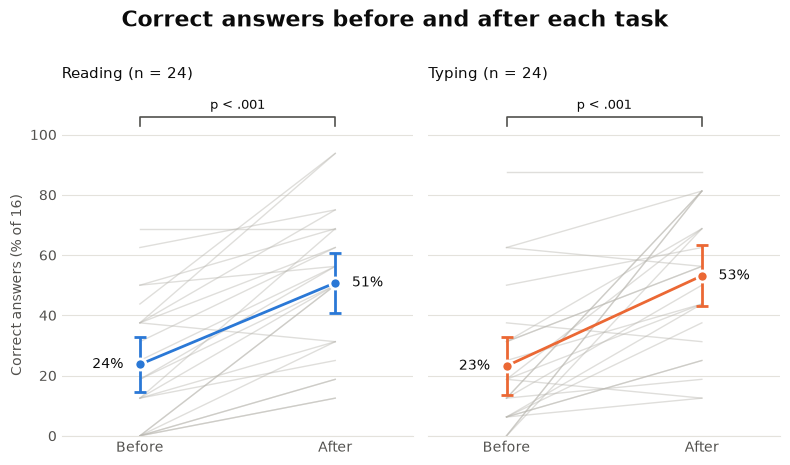

Note: Coloured points: mean with 95% confidence interval. Grey lines: individual participants. p: paired t-test, after vs before. Raw p values; Holm correction would not change any conclusion.


In [5]:
COLOR = {"Reading": "#2a78d6", "Typing": "#eb6834"}          # colour-blind-safe pair
INK, MUTED, RULE, SURFACE = "#0b0b0b", "#52514e", "#e4e2dc", "#ffffff"   # SURFACE: white background
TITLE = dict(color=INK, fontsize=16, fontweight="bold")                 # main titles, centred over each figure
FIGS, NOTES = {}, {}      # graphs by file name, exported in the last cell; the note for each is printed under it

def centre_title(fig, title):
    # centre the main title (and any figure legend) over the saved image, which the export crops to its content
    moving = [title, *fig.legends]
    for a in moving:
        a.set_visible(False)
    box = fig.get_tightbbox(fig.canvas.get_renderer())                  # everything else, in inches
    for a in moving:
        a.set_visible(True)
    x = (box.x0 + box.x1) / 2 / fig.get_figwidth()
    title.set_x(x)
    for leg in fig.legends:                                             # legend stays under the title
        y = leg.get_bbox_to_anchor().transformed(fig.transFigure.inverted()).y0
        leg.set_bbox_to_anchor((x, y), transform=fig.transFigure)

def bracket(ax, a, b, at, size, text, vertical=False, color=MUTED):
    # joins positions a and b with a bracket drawn at `at` and writes the p value beside it
    if vertical:   # bars: a and b are y positions, bracket to the right of the bars
        ax.plot([at - size, at, at, at - size], [a, a, b, b], color=color, lw=1.2, clip_on=False)
        ax.text(at + size, (a + b) / 2, text, ha="left", va="center", color=INK, fontsize=9.5)
    else:          # points: a and b are x positions, bracket above them
        ax.plot([a, a, b, b], [at - size, at, at, at - size], color=color, lw=1.2, clip_on=False)
        ax.text((a + b) / 2, at + size / 2, text, ha="center", va="bottom", color=INK, fontsize=9.5)

PT = {task: res.loc[f"{task}: after − before", "p"] for task in ("Reading", "Typing")}    # from the results table
fig, axes = plt.subplots(1, 2, figsize=(8, 4.7), sharey=True, facecolor=SURFACE)
for ax, task in zip(axes, ["Reading", "Typing"]):
    pre, post = W["pre"][task], W["post"][task]
    for a, b in zip(pre, post):                                   # each participant, faint
        ax.plot([0, 1], [a, b], color="#b9b7b0", lw=1, alpha=0.45, zorder=1)
    means = [pre.mean(), post.mean()]
    ci = [stats.t.ppf(0.975, len(s) - 1) * s.std(ddof=1) / np.sqrt(len(s)) for s in (pre, post)]
    ax.errorbar([0, 1], means, yerr=ci, color=COLOR[task], lw=2, marker="o", ms=8, mec=SURFACE, mew=2,
                capsize=4, zorder=3)
    for x, m in zip([0, 1], means):
        ax.annotate(f"{m:.0f}%", (x, m), xytext=(12 if x else -12, 0), textcoords="offset points",
                    ha="left" if x else "right", va="center", color=INK, fontsize=10)
    bracket(ax, 0, 1, 106, 3, plab(PT[task]))
    ax.set_title(f"{task} (n = {len(pre)})", loc="left", color=INK, fontsize=11)
    ax.set_facecolor(SURFACE); ax.set_xticks([0, 1], ["Before", "After"]); ax.set_xlim(-0.4, 1.4)
    ax.set_ylim(0, 116); ax.set_yticks(range(0, 101, 20))           # room above 100% for the bracket
    ax.yaxis.grid(True, color=RULE, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(RULE); ax.tick_params(colors=MUTED, length=0)
axes[0].set_ylabel("Correct answers (% of 16)", color=MUTED); axes[0].yaxis.label.set_y(50 / 116)
title = fig.suptitle("Correct answers before and after each task", **TITLE)
NOTES["before_after_by_task"] = ("Coloured points: mean with 95% confidence interval. Grey lines: individual "
                                 "participants. p: paired t-test, after vs before. " + p_note(list(PT.values())))
fig.tight_layout(rect=(0, 0, 1, 0.97))
centre_title(fig, title)
FIGS["before_after_by_task"] = fig
plt.show()
print("Note:", NOTES["before_after_by_task"])

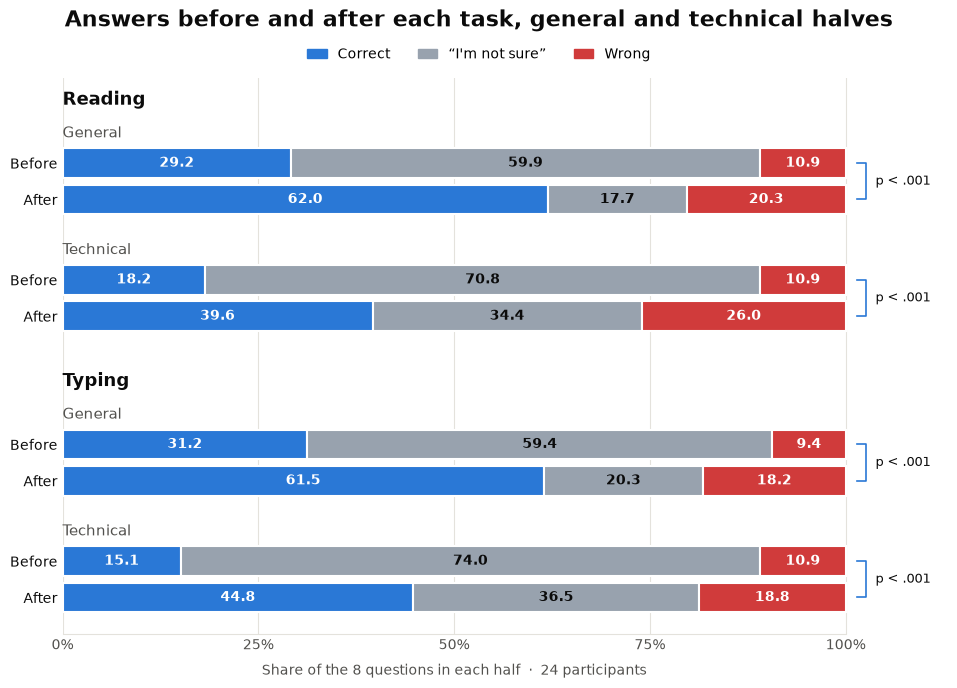

Note: p: paired t-test on correct answers, after vs before. Raw p values; Holm correction would not change any conclusion.


In [6]:
# share of the 8 questions in each half answered correctly, "not sure" or wrong, before and after
PART = [("correct", "Correct", "#2a78d6", "white"), ("notsure", "“I'm not sure”", "#98a2ae", INK),
        ("wrong", "Wrong", "#d03b3b", "white")]
comp = H.groupby(["task", "half"])[[f"{k}_{ph}" for k, *_ in PART for ph in ("pre", "post")]].mean() / 8 * 100
PC = {(t, h): res.loc[f"{t}, {h.lower()} half: after − before", "p"] for t in ("Reading", "Typing")
      for h in ("General", "Technical")}                       # correct answers, from the results table
XMAX = 113                                                     # room right of the bars for the p values

fig, ax = plt.subplots(figsize=(10, 6.9), facecolor=SURFACE); ax.set_facecolor(SURFACE)   # wide enough for the title
y, ticks, labels = 0, [], []
for task in ("Reading", "Typing"):
    ax.text(0, y, task, fontsize=13, fontweight="bold", color=INK, va="center"); y -= 0.7
    for half in ("General", "Technical"):
        ax.text(0, y, half, fontsize=11, color=MUTED, va="center"); y -= 0.62     # label sits just above its bars
        for ph, lab in (("pre", "Before"), ("post", "After")):
            left = 0
            for k, name, col, txt in PART:
                v = comp.loc[(task, half), f"{k}_{ph}"]
                ax.barh(y, v, left=left, height=0.62, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=3)
                if v >= 5:
                    ax.text(left + v / 2, y, f"{v:.1f}", ha="center", va="center", fontsize=10, color=txt,
                            fontweight="bold", zorder=4)
                left += v
            ticks.append(y); labels.append(lab); y -= 0.76
        bracket(ax, ticks[-2], ticks[-1], 102.6, 1.2, plab(PC[task, half]), vertical=True, color=PART[0][2])
        y -= 0.3
    y -= 0.3
ax.set_yticks(ticks, labels, color=INK); ax.set_xlim(0, XMAX); ax.set_ylim(y + 0.6, 0.45)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"], color=MUTED)
ax.grid(axis="x", color=RULE, lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(RULE); ax.spines["bottom"].set_bounds(0, 100); ax.tick_params(length=0)
ax.set_xlabel(f"Share of the 8 questions in each half  ·  {S.pid.nunique()} participants", color=MUTED, labelpad=8)
ax.xaxis.label.set_x(50 / XMAX)                                # centred under the bars
title = fig.suptitle("Answers before and after each task, general and technical halves", y=0.985, **TITLE)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col) for _, _, col, _ in PART], labels=[n for _, n, _, _ in PART],
           loc="upper center", bbox_to_anchor=(0.5, 0.948), ncol=3, frameon=False, handlelength=1.4)
NOTES["before_after_general_technical"] = ("p: paired t-test on correct answers, after vs before. "
                                           + p_note(list(PC.values())))
fig.subplots_adjust(left=0.09, right=0.975, top=0.885, bottom=0.08)
centre_title(fig, title)
FIGS["before_after_general_technical"] = fig
plt.show()
print("Note:", NOTES["before_after_general_technical"])

Proportional gain: 1 = all correct after, 0 = no change. Task rows: mean gain, tested against 0. Effect size: dz.


,n,difference,95% CI,t,df,p,p (Holm),effect size
"Reading, general half: proportional gain",24,+0.48,"[+0.34, +0.61]",7.21,23,<.001,,1.47
"Reading, technical half: proportional gain",24,+0.25,"[+0.13, +0.38]",4.26,23,<.001,,0.87
"Typing, general half: proportional gain",24,+0.43,"[+0.26, +0.61]",5.23,23,<.001,,1.07
"Typing, technical half: proportional gain",24,+0.27,"[+0.11, +0.43]",3.45,23,.002,,0.70
"Reading − typing proportional gain, general half",24,+0.04,"[-0.19, +0.27]",0.39,23,.703,1.000,0.08
"Reading − typing proportional gain, technical half",24,-0.02,"[-0.22, +0.19]",-0.16,23,.872,1.000,-0.03


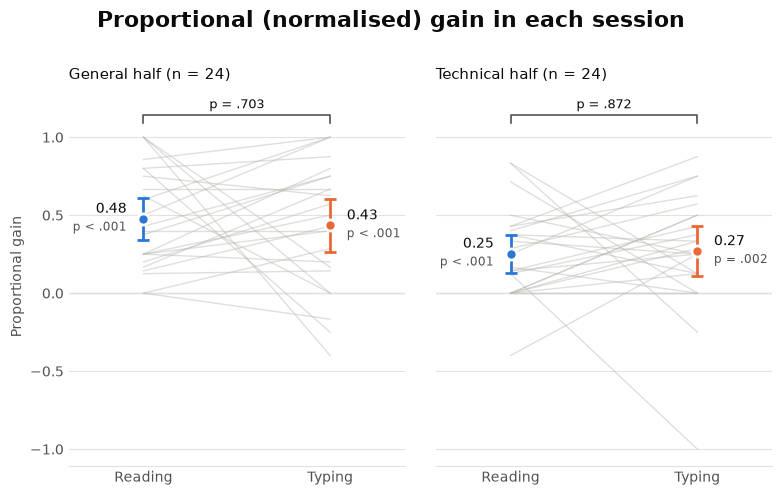

Note: (after − before) ÷ (100% − before): 1 = all correct after, 0 = no change, below 0 = fewer correct than before. Coloured points: mean with 95% CI and p vs 0 (one-sample t-test). Bracket: reading vs typing (paired t-test). Grey lines: each participant's two sessions. Raw p values; Holm correction would not change any conclusion.


In [7]:
# proportional (normalised) gain per half: each task against 0, and reading − typing for the same participants
NG = H.pivot_table(index="pid", columns=["half", "task"], values="ngain")      # NaN if 8/8 before: g undefined
tests = {}
for task in ("Reading", "Typing"):
    for half in ("General", "Technical"):
        tests[f"{task}, {half.lower()} half: proportional gain"] = paired(NG[half, task].dropna(), 0)
for half in ("General", "Technical"):
    X = NG[half].dropna()
    tests[f"Reading − typing proportional gain, {half.lower()} half"] = paired(X.Reading, X.Typing)
pg = pd.DataFrame(tests).T.astype(float)
rt_rows = pg.index[-2:]
pg.loc[rt_rows, "p (Holm)"] = holm(pg.loc[rt_rows, "p"])          # Holm correction for the two halves, as above
print("Proportional gain: 1 = all correct after, 0 = no change. Task rows: mean gain, tested against 0. Effect size: dz.")
display(fmt_table(pg, digits=2))

fig, axes = plt.subplots(1, 2, figsize=(8, 5.0), sharey=True, facecolor=SURFACE)
for ax, half in zip(axes, ["General", "Technical"]):
    X = NG[half].dropna()
    for a, b in zip(X.Reading, X.Typing):                          # each participant's two sessions, faint
        ax.plot([0, 1], [a, b], color="#b9b7b0", lw=1, alpha=0.45, zorder=1)
    for x, task in enumerate(["Reading", "Typing"]):
        r = pg.loc[f"{task}, {half.lower()} half: proportional gain"]
        ax.errorbar(x, r["diff"], yerr=r["hi"] - r["diff"], color=COLOR[task], lw=2, marker="o", ms=8, mec=SURFACE,
                    mew=2, capsize=4, zorder=3)
        dx, ha = (-12, "right") if x == 0 else (12, "left")       # mean above, its p (vs 0) below
        ax.annotate(f"{r['diff']:.2f}", (x, r["diff"]), xytext=(dx, 2), textcoords="offset points", ha=ha, va="bottom",
                    color=INK, fontsize=10)
        ax.annotate(plab(r["p"]), (x, r["diff"]), xytext=(dx, -2), textcoords="offset points", ha=ha, va="top",
                    color=MUTED, fontsize=8.5)
    bracket(ax, 0, 1, 1.14, 0.05, plab(pg.loc[f"Reading − typing proportional gain, {half.lower()} half", "p"]))
    ax.axhline(0, color=MUTED, lw=0.8, zorder=0)
    ax.set_title(f"{half} half (n = {len(X)})", loc="left", color=INK, fontsize=11)
    ax.set_facecolor(SURFACE); ax.set_xticks([0, 1], ["Reading", "Typing"]); ax.set_xlim(-0.4, 1.4)
    ax.yaxis.grid(True, color=RULE, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(RULE); ax.tick_params(colors=MUTED, length=0)
axes[0].set_ylim(top=1.32)                                         # room above 1 for the brackets
lo = axes[0].get_ylim()[0]
axes[0].set_yticks([t for t in axes[0].get_yticks() if lo <= t <= 1])
axes[0].set_ylabel("Proportional gain", color=MUTED)
title = fig.suptitle("Proportional (normalised) gain in each session", **TITLE)
NOTES["proportional_gain"] = ("(after − before) ÷ (100% − before): 1 = all correct after, 0 = no change, below 0 = "
                              "fewer correct than before. Coloured points: mean with 95% CI and p vs 0 (one-sample "
                              "t-test). Bracket: reading vs typing (paired t-test). Grey lines: each participant's "
                              "two sessions. " + p_note(pg.p))
fig.tight_layout(rect=(0, 0, 1, 0.97))
centre_title(fig, title)
FIGS["proportional_gain"] = fig
plt.show()
print("Note:", NOTES["proportional_gain"])

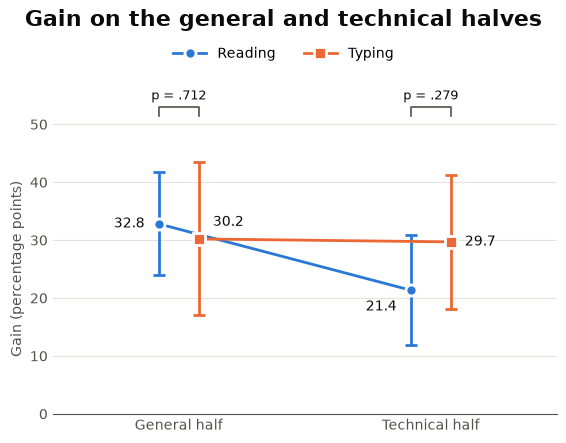

Note: Points: mean gain (after − before) with 95% confidence interval, 24 participants. Brackets: reading vs typing on each half (paired t-test). Raw p values; Holm correction would not change any conclusion.


In [8]:
# gain (after − before) on each half, reading vs typing: means and 95% CIs from the results table (res)
from matplotlib.lines import Line2D
HALVES, TASKS = ("General", "Technical"), ("Reading", "Typing")
GH = {(t, h): res.loc[f"{t}, {h.lower()} half: after − before"] for t in TASKS for h in HALVES}
PRT = {h: res.loc[f"Reading − typing gain, {h.lower()} half", "p"] for h in HALVES}    # brackets: reading vs typing
X = {"Reading": np.array([-0.08, 0.92]), "Typing": np.array([0.08, 1.08])}            # side by side: CIs stay apart
M = {t: np.array([GH[t, h]["diff"] for h in HALVES]) for t in TASKS}
MARK = {"Reading": "o", "Typing": "s"}                                                # shape as well as colour
TOP = 10 * np.ceil(max(r["hi"] for r in GH.values()) / 10)                            # highest tick
LOW = min(0, 10 * np.floor(min(r["lo"] for r in GH.values()) / 10))
YMAX = TOP + 0.16 * (TOP - LOW)                                                       # room above for the brackets

fig, ax = plt.subplots(figsize=(6, 4.6), facecolor=SURFACE); ax.set_facecolor(SURFACE)
for t in TASKS:
    lo, hi = (np.array([GH[t, h][k] for h in HALVES]) for k in ("lo", "hi"))
    ax.errorbar(X[t], M[t], yerr=[M[t] - lo, hi - M[t]], color=COLOR[t], lw=2, marker=MARK[t], ms=8, mec=SURFACE,
                mew=2, capsize=4, zorder=3)
for t, other, side in (("Reading", "Typing", -1), ("Typing", "Reading", 1)):   # Reading's values on its left,
    for i, (x, m) in enumerate(zip(X[t], M[t])):                              # Typing's on its right
        dy = 0
        if (side == 1) == (i == 0):        # this side faces the lines between the halves: go above or below them
            xm = x + side * 0.2
            dy = 7 if np.interp(xm, X[t], M[t]) >= np.interp(xm, X[other], M[other]) else -7
        ax.annotate(f"{m:.1f}", (x, m), xytext=(10 * side, dy), textcoords="offset points", color=INK, fontsize=10,
                    ha="left" if side > 0 else "right", va="center" if dy == 0 else ("bottom" if dy > 0 else "top"))
for c, h in enumerate(HALVES):
    bracket(ax, c - 0.08, c + 0.08, TOP + 0.06 * (TOP - LOW), 0.03 * (TOP - LOW), plab(PRT[h]))
ax.axhline(0, color=MUTED, lw=0.8, zorder=1, clip_on=False)                           # 0 = no change
ax.set_xticks([0, 1], [f"{h} half" for h in HALVES]); ax.set_xlim(-0.5, 1.5)
ax.set_ylim(LOW, YMAX); ax.set_yticks(np.arange(LOW, TOP + 1, 10))
ax.yaxis.grid(True, color=RULE, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left", "bottom"):
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.set_ylabel("Gain (percentage points)", color=MUTED); ax.yaxis.label.set_y((TOP - LOW) / 2 / (YMAX - LOW))
title = fig.suptitle("Gain on the general and technical halves", **TITLE)
fig.legend([Line2D([0], [0], color=COLOR[t], lw=2, marker=MARK[t], ms=8, mec=SURFACE, mew=2) for t in TASKS], TASKS,
           loc="upper center", bbox_to_anchor=(0.5, 0.925), ncol=2, frameon=False, handlelength=2.4)
NOTES["gain_general_technical"] = (f"Points: mean gain (after − before) with 95% confidence interval, "
                                   f"{int(GH['Reading', 'General']['n'])} participants. Brackets: reading vs "
                                   "typing on each half (paired t-test). " + p_note(list(PRT.values())))
fig.subplots_adjust(left=0.13, right=0.97, top=0.83, bottom=0.1)
centre_title(fig, title)
FIGS["gain_general_technical"] = fig
plt.show()
print("Note:", NOTES["gain_general_technical"])

In [9]:
# export every graph to FIG_DIR: PNG (300 dpi) for Word or slides, PDF (vector) for LaTeX; notes in figure_notes.txt
FIG_DIR.mkdir(parents=True, exist_ok=True)
saved = []
with plt.rc_context({"pdf.fonttype": 42}):                     # PDF text kept as TrueType: editable, accepted by publishers
    for name, f in FIGS.items():
        for ext, dpi in (("png", 300), ("pdf", None)):
            f.savefig(FIG_DIR / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", facecolor=f.get_facecolor())
            saved.append(f"{name}.{ext}")
(FIG_DIR / "figure_notes.txt").write_text("\n\n".join(f"{name}: {note}" for name, note in NOTES.items()) + "\n",
                                          encoding="utf-8")
saved.append("figure_notes.txt")
print(f"Exported {len(saved)} files to {FIG_DIR.resolve()}:", *saved, sep="\n  ")

Exported 9 files to C:\Users\ASUS\Master's research:
  before_after_by_task.png
  before_after_by_task.pdf
  before_after_general_technical.png
  before_after_general_technical.pdf
  proportional_gain.png
  proportional_gain.pdf
  gain_general_technical.png
  gain_general_technical.pdf
  figure_notes.txt
